# Pandas Comprehensive 
## Data Manipulation and Analysis

## Text Data, MultiIndex, Merging

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Set display options
pd.set_option('display.max_columns', 10)
# This tells Pandas:
# "When printing a DataFrame, show at most 10 columns."
pd.set_option('display.width', 1000)
# This controls how wide the printed table is before Pandas wraps it onto another line.

## 1. Working with Text Data

### 1.1 Dataset: Chicago Employee Records

In [2]:
# Load the dataset
chicago = pd.read_csv("chicago.csv").dropna(how="all")
chicago.head()

,Name,Position Title,Department,Employee Annual Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00"
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00"
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


In [3]:
# Basic information
chicago.info()

<class 'pandas.DataFrame'>
RangeIndex: 32062 entries, 0 to 32061
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Name                    32062 non-null  str  
 1   Position Title          32062 non-null  str  
 2   Department              32062 non-null  str  
 3   Employee Annual Salary  32062 non-null  str  
dtypes: str(4)
memory usage: 1002.1 KB


In [4]:
# Number of unique values in each column
chicago.nunique()

Name                      31776
Position Title             1093
Department                   35
Employee Annual Salary     1156
dtype: int64

In [5]:
# Convert Department to categorical
chicago["Department"] = chicago["Department"].astype("category")
chicago.info()

<class 'pandas.DataFrame'>
RangeIndex: 32062 entries, 0 to 32061
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Name                    32062 non-null  str     
 1   Position Title          32062 non-null  str     
 2   Department              32062 non-null  category
 3   Employee Annual Salary  32062 non-null  str     
dtypes: category(1), str(3)
memory usage: 783.2 KB


### 1.2 Common String Methods

In [6]:
# String methods on Position Title
print(chicago["Position Title"].str.lower().head())
print(chicago["Position Title"].str.upper().head())
print(chicago["Position Title"].str.title().head())
print(chicago["Position Title"].str.len().head())
print(chicago["Position Title"].str.strip().head())

0            water rate taker
1              police officer
2              police officer
3    chief contract expediter
4           civil engineer iv
Name: Position Title, dtype: str
0            WATER RATE TAKER
1              POLICE OFFICER
2              POLICE OFFICER
3    CHIEF CONTRACT EXPEDITER
4           CIVIL ENGINEER IV
Name: Position Title, dtype: str
0            Water Rate Taker
1              Police Officer
2              Police Officer
3    Chief Contract Expediter
4           Civil Engineer Iv
Name: Position Title, dtype: str
0    16
1    14
2    14
3    24
4    17
Name: Position Title, dtype: int64
0            WATER RATE TAKER
1              POLICE OFFICER
2              POLICE OFFICER
3    CHIEF CONTRACT EXPEDITER
4           CIVIL ENGINEER IV
Name: Position Title, dtype: str


In [7]:
# Replace text in Department column
chicago["Department"].str.replace("MGMNT", "MANAGEMENT").str.title().head()

0    Water Management
1              Police
2              Police
3    General Services
4    Water Management
Name: Department, dtype: str

In [8]:
# How do I know whether .00, ,, $ etc. are actually
# stored in the data, or whether Pandas is just displaying them nicely?




In [9]:
# one way to identify
salary = chicago.loc[0, "Employee Annual Salary"]
print(salary)
print(type(salary))
for ch in salary:
    print(ch)


# another way to identify
print(len(salary))

$90,744.00
<class 'str'>
$
9
0
,
7
4
4
.
0
0
10


In [10]:
# Converting this salary column to numeric
# First remove the unwanted characters.

In [11]:
chicago["Employee Annual Salary"]=chicago["Employee Annual Salary"].str.replace("$", "", regex = False)
# Without regex=False
# .str.replace("$", "")

# Now Pandas has to decide whether $ is a regex pattern or a normal string.

# In regular expressions,

# $

# means:

# End of the string

# It does not mean the dollar sign.

# So if regex is being used, Pandas will try to match the end of every string, not the $ character.

# For example:

# s = pd.Series(["$90", "$100"])

# If regex interprets $ as "end of string", then

# s.str.replace("$", "")

# is not replacing the dollar sign—it's matching the position at the end of the string.

In [12]:
chicago[~chicago["Employee Annual Salary"].str.endswith(".00")]

,Name,Position Title,Department,Employee Annual Salary
6,"ABARCA, EMMANUEL",GENERAL LABORER - DSS,STREETS & SAN,"41,849.60"
7,"ABASCAL, REECE E",TRAFFIC CONTROL AIDE-HOURLY,OEMC,"20,051.20"
23,"ABDULLAH, LAKENYA N",CROSSING GUARD,OEMC,"17,846.40"
26,"ABDUL-SHAKUR, TAHIR",GENERAL LABORER - DSS,STREETS & SAN,"41,849.60"
30,"ABERCROMBIE, TIMOTHY",MOTOR TRUCK DRIVER,STREETS & SAN,"72,862.40"
...,...,...,...,...
32030,"ZUMMO, ROBERT J",MOTOR TRUCK DRIVER,STREETS & SAN,"72,862.40"
32036,"ZUNIGA, THOMAS",GENERAL LABORER - DSS,STREETS & SAN,"43,201.60"
32038,"ZUNO, ERIK",LABORER - APPRENTICE,WATER MGMNT,"73,382.40"
32049,"ZWARYCZ MANN, IRENE A",CROSSING GUARD,OEMC,"17,024.80"


In [13]:
chicago["Employee Annual Salary"]=chicago["Employee Annual Salary"].str.replace(".00", "", regex = False)

In [14]:
chicago["Employee Annual Salary"]=chicago["Employee Annual Salary"].str.replace(",", "", regex = False)

In [15]:
chicago[chicago["Employee Annual Salary"].str.endswith(".60")]

,Name,Position Title,Department,Employee Annual Salary
6,"ABARCA, EMMANUEL",GENERAL LABORER - DSS,STREETS & SAN,41849.60
26,"ABDUL-SHAKUR, TAHIR",GENERAL LABORER - DSS,STREETS & SAN,41849.60
44,"ABREU, EDWIN",TREE TRIMMER,STREETS & SAN,75961.60
156,"ADDISON, LATASHA D",LIBRARY CLERK - HOURLY,PUBLIC LIBRARY,16317.60
250,"AHMAD, FAROOQ",LABORER,AVIATION,69825.60
...,...,...,...,...
31945,"ZICKTERMAN, KEVIN A",LAW CLERK,LAW,25898.60
31975,"ZINCHUK, BRIAN C",OPERATING ENGINEER-GROUP C,WATER MGMNT,93745.60
31994,"ZOCHOWSKI, DAVID J",OPERATING ENGINEER-GROUP C,AVIATION,93745.60
32028,"ZUMARAS, ROLAND A",AIRPORT MAINTENANCE FOREMAN,AVIATION,71905.60


In [16]:
chicago["Employee Annual Salary"]

0         90744
1         84450
2         84450
3         89880
4        106836
          ...  
32057     99528
32058     87384
32059     84450
32060     87384
32061    113664
Name: Employee Annual Salary, Length: 32062, dtype: str

In [17]:
chicago[chicago["Employee Annual Salary"].str.endswith(".60")]

,Name,Position Title,Department,Employee Annual Salary
6,"ABARCA, EMMANUEL",GENERAL LABORER - DSS,STREETS & SAN,41849.60
26,"ABDUL-SHAKUR, TAHIR",GENERAL LABORER - DSS,STREETS & SAN,41849.60
44,"ABREU, EDWIN",TREE TRIMMER,STREETS & SAN,75961.60
156,"ADDISON, LATASHA D",LIBRARY CLERK - HOURLY,PUBLIC LIBRARY,16317.60
250,"AHMAD, FAROOQ",LABORER,AVIATION,69825.60
...,...,...,...,...
31945,"ZICKTERMAN, KEVIN A",LAW CLERK,LAW,25898.60
31975,"ZINCHUK, BRIAN C",OPERATING ENGINEER-GROUP C,WATER MGMNT,93745.60
31994,"ZOCHOWSKI, DAVID J",OPERATING ENGINEER-GROUP C,AVIATION,93745.60
32028,"ZUMARAS, ROLAND A",AIRPORT MAINTENANCE FOREMAN,AVIATION,71905.60


In [18]:
chicago["Employee Annual Salary"].astype(float)

0         90744.0
1         84450.0
2         84450.0
3         89880.0
4        106836.0
           ...   
32057     99528.0
32058     87384.0
32059     84450.0
32060     87384.0
32061    113664.0
Name: Employee Annual Salary, Length: 32062, dtype: float64

In [19]:
# our employee salary does contain . values the following code just check out 
# whether the entire cell has . value or not so obvi it will return empty series
chicago["Employee Annual Salary"][chicago["Employee Annual Salary"]=="."]

Series([], Name: Employee Annual Salary, dtype: str)

In [20]:
chicago["Employee Annual Salary"]=chicago["Employee Annual Salary"].astype(float)

In [21]:
# while converting into int the float values has been discarded
chicago["Employee Annual Salary"]=chicago["Employee Annual Salary"].astype(int)

In [22]:
type(chicago["Employee Annual Salary"][0])

numpy.int64

In [23]:
chicago["Employee Annual Salary"][31975]

np.int64(93745)

In [24]:
chicago["Employee Annual Salary"].mean()

np.float64(80204.11786538581)

In [25]:
chicago["Employee Annual Salary"].min()

np.int64(0)

In [26]:
print(chicago.shape)
chicago["Employee Annual Salary"].describe()

(32062, 4)


count     32062.000000
mean      80204.117865
std       25098.387386
min           0.000000
25%       72862.000000
50%       84450.000000
75%       93240.000000
max      300000.000000
Name: Employee Annual Salary, dtype: float64

In [27]:
chicago["Employee Annual Salary"][chicago["Employee Annual Salary"]==0]

15102    0
Name: Employee Annual Salary, dtype: int64

In [28]:
chicago["Employee Annual Salary"].std()

np.float64(25098.387385504386)

In [29]:
chicago["Employee Annual Salary"].max()

np.int64(300000)

In [30]:
chicago["Position Title"]

0                      WATER RATE TAKER
1                        POLICE OFFICER
2                        POLICE OFFICER
3              CHIEF CONTRACT EXPEDITER
4                     CIVIL ENGINEER IV
                      ...              
32057    FRM OF MACHINISTS - AUTOMOTIVE
32058                    POLICE OFFICER
32059                    POLICE OFFICER
32060                    POLICE OFFICER
32061           CHIEF DATA BASE ANALYST
Name: Position Title, Length: 32062, dtype: str

### 1.3 Filtering with String Methods

In [31]:
# Filtering with contains
water_workers = chicago["Position Title"].str.lower().str.contains("water")
chicago[water_workers].head()

,Name,Position Title,Department,Employee Annual Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,90744
554,"ALUISE, VINCENT G",FOREMAN OF WATER PIPE CONSTRUCTION,WATER MGMNT,102440
671,"ANDER, PERRY A",WATER CHEMIST II,WATER MGMNT,82044
685,"ANDERSON, ANDREW J",DISTRICT SUPERINTENDENT OF WATER DISTRIBUTION,WATER MGMNT,109272
702,"ANDERSON, DONALD",FOREMAN OF WATER PIPE CONSTRUCTION,WATER MGMNT,102440


In [32]:
# to show the total number of water_workers
chicago[water_workers].shape

(111, 4)

In [33]:
# Filtering with startswith
starts_with_civil = chicago["Position Title"].str.lower().str.startswith("civil")
print(chicago.loc[starts_with_civil].head())

print(chicago[starts_with_civil].head())
# Notice that after .lower(), the result is still a Series.
# If you chain another string method afterward, the result is still a Series, so you need .str again:
# Series.str.method1().str.method2().str.method3()


# while chicago[mask] is fine for filtering rows, .loc becomes especially useful
# when you also want to choose specific columns.

                     Name     Position Title   Department  Employee Annual Salary
4     ABAD JR,  VICENTE M  CIVIL ENGINEER IV  WATER MGMNT                  106836
25   ABDULSATTAR,  MUDHAR  CIVIL ENGINEER II  WATER MGMNT                   58536
34     ABRAHAM,  GIRLEY T  CIVIL ENGINEER IV  WATER MGMNT                  106836
55     ABUTALEB,  AHMAD H  CIVIL ENGINEER II  WATER MGMNT                   89676
147      ADAMS,  TANERA C  CIVIL ENGINEER IV   TRANSPORTN                  106836
                     Name     Position Title   Department  Employee Annual Salary
4     ABAD JR,  VICENTE M  CIVIL ENGINEER IV  WATER MGMNT                  106836
25   ABDULSATTAR,  MUDHAR  CIVIL ENGINEER II  WATER MGMNT                   58536
34     ABRAHAM,  GIRLEY T  CIVIL ENGINEER IV  WATER MGMNT                  106836
55     ABUTALEB,  AHMAD H  CIVIL ENGINEER II  WATER MGMNT                   89676
147      ADAMS,  TANERA C  CIVIL ENGINEER IV   TRANSPORTN                  106836


In [34]:
chicago.loc[starts_with_civil].shape

(70, 4)

In [35]:
# Filtering with endswith
ends_with_iv = chicago["Position Title"].str.lower().str.endswith("iv")
chicago[ends_with_iv].head()

,Name,Position Title,Department,Employee Annual Salary
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,106836
34,"ABRAHAM, GIRLEY T",CIVIL ENGINEER IV,WATER MGMNT,106836
145,"ADAMS, SHERYLL A",LIBRARIAN IV,PUBLIC LIBRARY,97812
147,"ADAMS, TANERA C",CIVIL ENGINEER IV,TRANSPORTN,106836
166,"ADENI, MOHAMED K",ACCOUNTANT IV,FINANCE,97812


### 1.4 String Methods on Index and Columns

In [36]:
# Setting Name as index
chicago_idx = pd.read_csv("chicago.csv", index_col="Name").dropna(how="all").sort_index()
chicago_idx["Department"] = chicago_idx["Department"].astype("category")
chicago_idx.head()

,Position Title,Department,Employee Annual Salary
Name,,,
"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00"
"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00"
"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


In [37]:
chicago_idx.dtypes

Position Title                 str
Department                category
Employee Annual Salary         str
dtype: object

In [38]:
# Clean the index
chicago_idx.index = chicago_idx.index.str.strip().str.title()
chicago_idx.head()

,Position Title,Department,Employee Annual Salary
Name,,,
"Aaron, Elvia J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
"Aaron, Jeffery M",POLICE OFFICER,POLICE,"$84,450.00"
"Aaron, Karina",POLICE OFFICER,POLICE,"$84,450.00"
"Aaron, Kimberlei R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
"Abad Jr, Vicente M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


In [39]:
# Clean column names
chicago_idx.columns = chicago_idx.columns.str.upper()
chicago_idx.head()

,POSITION TITLE,DEPARTMENT,EMPLOYEE ANNUAL SALARY
Name,,,
"Aaron, Elvia J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
"Aaron, Jeffery M",POLICE OFFICER,POLICE,"$84,450.00"
"Aaron, Karina",POLICE OFFICER,POLICE,"$84,450.00"
"Aaron, Kimberlei R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
"Abad Jr, Vicente M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


### 1.5 The split Method

In [40]:
# Split Position Title and extract first word
# Pandas StringAccessor (.str):
# When you write foods["Frequency_Item"].str, Pandas gives you access to a suite of vectorised string and sequence operations designed for Series.

# Pandas explicitly added .str.get() to the StringAccessor to make accessing elements from sequence-like objects (like lists or strings inside Series cells) safe and easy.
chicago["Position Title"].str.split(" ").str.get(0).value_counts().head(10)

Position Title
POLICE             10856
FIREFIGHTER-EMT     1509
SERGEANT            1186
POOL                 918
FIREFIGHTER          810
CROSSING             775
MOTOR                721
SANITATION           715
PARAMEDIC            641
ASST                 606
Name: count, dtype: int64

In [41]:
# this is way of extracting the first word
chicago["Position Title"].str.split(" ").str.get(0)

0         WATER
1        POLICE
2        POLICE
3         CHIEF
4         CIVIL
          ...  
32057       FRM
32058    POLICE
32059    POLICE
32060    POLICE
32061     CHIEF
Name: Position Title, Length: 32062, dtype: object

In [42]:
# Split Name into Last and First
chicago[["Last Name", "First Name"]] = chicago["Name"].str.split(",", expand=True)
chicago.head()

,Name,Position Title,Department,Employee Annual Salary,Last Name,First Name
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,90744,AARON,ELVIA J
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,84450,AARON,JEFFERY M
2,"AARON, KARINA",POLICE OFFICER,POLICE,84450,AARON,KARINA
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,89880,AARON,KIMBERLEI R
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,106836,ABAD JR,VICENTE M


In [43]:
# Split with n parameter
chicago[["Primary Title", "Secondary Title"]] = chicago["Position Title"].str.split(" ", expand=True, n=1)
chicago.head()

,Name,Position Title,Department,Employee Annual Salary,Last Name,First Name,Primary Title,Secondary Title
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,90744,AARON,ELVIA J,WATER,RATE TAKER
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,84450,AARON,JEFFERY M,POLICE,OFFICER
2,"AARON, KARINA",POLICE OFFICER,POLICE,84450,AARON,KARINA,POLICE,OFFICER
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,89880,AARON,KIMBERLEI R,CHIEF,CONTRACT EXPEDITER
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,106836,ABAD JR,VICENTE M,CIVIL,ENGINEER IV


In [44]:
# Split with n parameter
chicago[["Primary Title", "Secondary Title", "Tertiary Title"]] = chicago["Position Title"].str.split(" ", expand=True, n=2)
chicago.head()
# this creates nan values in the tertiary title column

,Name,Position Title,Department,Employee Annual Salary,Last Name,First Name,Primary Title,Secondary Title,Tertiary Title
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,90744,AARON,ELVIA J,WATER,RATE,TAKER
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,84450,AARON,JEFFERY M,POLICE,OFFICER,NaN
2,"AARON, KARINA",POLICE OFFICER,POLICE,84450,AARON,KARINA,POLICE,OFFICER,NaN
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,89880,AARON,KIMBERLEI R,CHIEF,CONTRACT,EXPEDITER
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,106836,ABAD JR,VICENTE M,CIVIL,ENGINEER,IV


In [45]:
# Find most common first names
chicago["Name"].str.title().str.split(", ").str.get(1).str.strip().str.split(" ").str.get(0).value_counts().head(10)

Name
Michael    1153
John        899
James       676
Robert      622
Joseph      537
David       506
Thomas      490
Daniel      472
William     397
Anthony     385
Name: count, dtype: int64

## 2. MultiIndex (Hierarchical Indexing)

### 2.1 Creating MultiIndex DataFrames

In [46]:
# Sample data for MultiIndex
sales_data = {
    'Product': ['A', 'A', 'A', 'B', 'B', 'B', 'C', 'C', 'C'],
    'Region': ['North', 'South', 'East', 'North', 'South', 'East', 'North', 'South', 'East'],
    'Sales': [100, 150, 120, 200, 180, 220, 80, 90, 85],
    'Profit': [20, 30, 25, 40, 35, 45, 15, 18, 17]
}
sales_df = pd.DataFrame(sales_data)
sales_df

,Product,Region,Sales,Profit
0,A,North,100,20
1,A,South,150,30
2,A,East,120,25
3,B,North,200,40
4,B,South,180,35
5,B,East,220,45
6,C,North,80,15
7,C,South,90,18
8,C,East,85,17


In [47]:
# Setting MultiIndex
multi_df = sales_df.set_index(['Product', 'Region'])
multi_df

Sales  Profit
Product Region               
A       North     100      20
        South     150      30
        East      120      25
B       North     200      40
        South     180      35
        East      220      45
C       North      80      15
        South      90      18
        East       85      17

In [48]:
# MultiIndex from arrays
arrays = [
    ['A', 'A', 'B', 'B', 'C', 'C'],
    ['North', 'South', 'North', 'South', 'North', 'South']
]
index = pd.MultiIndex.from_arrays(arrays, names=['Product', 'Region'])
df_multi = pd.DataFrame({'Sales': [100, 150, 200, 180, 80, 90]}, index=index)
df_multi

Sales
Product Region       
A       North     100
        South     150
B       North     200
        South     180
C       North      80
        South      90

In [49]:
# from_arrays() creates a MultiIndex from multiple lists.
# Each list becomes one level of the index.
# names= gives names to those index levels.
# The resulting DataFrame has hierarchical row labels instead of a single numeric index.

# A MultiIndex is useful when your data is naturally identified by more than one key, such as:

# Product → Region
# Year → Month
# Country → City

### 2.2 Accessing Data in MultiIndex

In [50]:
# Using .loc with MultiIndex
multi_df.loc['A']  # All entries for Product A

,Sales,Profit
Region,,
North,100,20
South,150,30
East,120,25


In [51]:
# Accessing specific combination
multi_df.loc[('A', 'North')]

Sales     100
Profit     20
Name: (A, North), dtype: int64

In [52]:
# Using xs (cross-section)
multi_df.xs('North', level='Region')  # All entries for North region

,Sales,Profit
Product,,
A,100,20
B,200,40
C,80,15


In [53]:
sales_df

,Product,Region,Sales,Profit
0,A,North,100,20
1,A,South,150,30
2,A,East,120,25
3,B,North,200,40
4,B,South,180,35
5,B,East,220,45
6,C,North,80,15
7,C,South,90,18
8,C,East,85,17


In [54]:
# Sorting MultiIndex
unsorted_multi = sales_df.set_index(['Region', 'Product']).sort_index(level=1) # it sorts by the second level which would be "Product"
unsorted_multi

,,Sales,Profit
Region,Product,,
East,A,120,25
North,A,100,20
South,A,150,30
East,B,220,45
North,B,200,40
South,B,180,35
East,C,85,17
North,C,80,15
South,C,90,18


In [55]:
# Sorting MultiIndex
unsorted_multi = sales_df.set_index(['Region', 'Product']).sort_index(level=0)#it sorts by the very first column of the index which is region
unsorted_multi

Sales  Profit
Region Product               
East   A          120      25
       B          220      45
       C           85      17
North  A          100      20
       B          200      40
       C           80      15
South  A          150      30
       B          180      35
       C           90      18

### 2.3 Stack and Unstack

In [56]:
multi_df

Sales  Profit
Product Region               
A       North     100      20
        South     150      30
        East      120      25
B       North     200      40
        South     180      35
        East      220      45
C       North      80      15
        South      90      18
        East       85      17

In [57]:
# Unstack: Convert row level to column
# unstack() means:
# Take one level of the row index and turn it into columns.
# multi_df.unstack(level="Region")

# means:

# Keep Product as the row index.
# Move Region from the row index to the columns.
# Place the corresponding Sales values in those new columns.
    
unstacked = multi_df.unstack(level='Region')
unstacked.info()

<class 'pandas.DataFrame'>
Index: 3 entries, A to C
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   (Sales, East)    3 non-null      int64
 1   (Sales, North)   3 non-null      int64
 2   (Sales, South)   3 non-null      int64
 3   (Profit, East)   3 non-null      int64
 4   (Profit, North)  3 non-null      int64
 5   (Profit, South)  3 non-null      int64
dtypes: int64(6)
memory usage: 276.0+ bytes


In [58]:
unstacked

Sales             Profit            
Region   East North South   East North South
Product                                     
A         120   100   150     25    20    30
B         220   200   180     45    40    35
C          85    80    90     17    15    18

In [59]:
# accessing the values
unstacked.loc["A"]["Sales","East"]

np.int64(120)

In [60]:
# Stack: Convert columns to rows
stacked = unstacked.stack()
stacked

Sales  Profit
Product Region               
A       East      120      25
        North     100      20
        South     150      30
B       East      220      45
        North     200      40
        South     180      35
C       East       85      17
        North      80      15
        South      90      18

## 3. Merging DataFrames

In [61]:
import numpy as np
# Create sample dataframes for merging
employees = pd.DataFrame({
    'EmployeeID': [101, 102, 103, 104, 105, 106],
    'Name': ['John', 'Jane', 'Bob', 'Alice', 'Charlie', 'Hemrn'],
    'DepartmentID': [1, 2, 1, 3, 2, np.nan]
})

departments = pd.DataFrame({
    'DepartmentID': [1, 2, 3, 4],
    'DeptName': ['HR', 'IT', 'Finance', 'Marketing'],
    'Manager': ['Sarah', 'Mike', 'Lisa', 'Tom']
})

salaries = pd.DataFrame({
    'EmployeeID': [101, 102, 103, 104, 105],
    'Salary': [60000, 75000, 55000, 80000, 70000],
    'Bonus': [5000, 8000, 4000, 10000, 7000]
    
})

print("Employees:")
print(employees)
print("\nDepartments:")
print(departments)
print("\nSalaries:")
print(salaries)

Employees:
   EmployeeID     Name  DepartmentID
0         101     John           1.0
1         102     Jane           2.0
2         103      Bob           1.0
3         104    Alice           3.0
4         105  Charlie           2.0
5         106    Hemrn           NaN

Departments:
   DepartmentID   DeptName Manager
0             1         HR   Sarah
1             2         IT    Mike
2             3    Finance    Lisa
3             4  Marketing     Tom

Salaries:
   EmployeeID  Salary  Bonus
0         101   60000   5000
1         102   75000   8000
2         103   55000   4000
3         104   80000  10000
4         105   70000   7000


### 3.1 Inner Join

In [62]:
# Inner join - only matching records
inner_join = pd.merge(employees, departments, on='DepartmentID', how='inner')
inner_join

,EmployeeID,Name,DepartmentID,DeptName,Manager
0,101,John,1.0,HR,Sarah
1,102,Jane,2.0,IT,Mike
2,103,Bob,1.0,HR,Sarah
3,104,Alice,3.0,Finance,Lisa
4,105,Charlie,2.0,IT,Mike


### 3.2 Left and Right Joins

In [63]:
# Left join - all employees, matching departments
left_join = pd.merge(employees, departments, on='DepartmentID', how='left')
left_join

,EmployeeID,Name,DepartmentID,DeptName,Manager
0,101,John,1.0,HR,Sarah
1,102,Jane,2.0,IT,Mike
2,103,Bob,1.0,HR,Sarah
3,104,Alice,3.0,Finance,Lisa
4,105,Charlie,2.0,IT,Mike
5,106,Hemrn,NaN,NaN,NaN


In [64]:
# Right join - all departments, matching employees
right_join = pd.merge(employees, departments, on='DepartmentID', how='right')
right_join

,EmployeeID,Name,DepartmentID,DeptName,Manager
0,101.0,John,1.0,HR,Sarah
1,103.0,Bob,1.0,HR,Sarah
2,102.0,Jane,2.0,IT,Mike
3,105.0,Charlie,2.0,IT,Mike
4,104.0,Alice,3.0,Finance,Lisa
5,NaN,NaN,4.0,Marketing,Tom


### 3.3 Outer Join

In [65]:
# Outer join - all records from both
outer_join = pd.merge(employees, departments, on='DepartmentID', how='outer')
outer_join

,EmployeeID,Name,DepartmentID,DeptName,Manager
0,101.0,John,1.0,HR,Sarah
1,103.0,Bob,1.0,HR,Sarah
2,102.0,Jane,2.0,IT,Mike
3,105.0,Charlie,2.0,IT,Mike
4,104.0,Alice,3.0,Finance,Lisa
5,NaN,NaN,4.0,Marketing,Tom
6,106.0,Hemrn,NaN,NaN,NaN


### 3.4 Merging with Different Column Names

In [66]:
# Example with different column names
emp_alt = pd.DataFrame({
    'EmpID': [101, 102, 103, 104, 105],
    'Name': ['John', 'Jane', 'Bob', 'Alice', 'Charlie'],
    'DeptID': [1, 2, 1, 3, 2]
})

pd.merge(emp_alt, departments, left_on='DeptID', right_on='DepartmentID')

,EmpID,Name,DeptID,DepartmentID,DeptName,Manager
0,101,John,1,1,HR,Sarah
1,102,Jane,2,2,IT,Mike
2,103,Bob,1,1,HR,Sarah
3,104,Alice,3,3,Finance,Lisa
4,105,Charlie,2,2,IT,Mike


### 3.5 Merging Multiple DataFrames

In [67]:
# Chain multiple merges
merged = employees.merge(departments, on='DepartmentID').merge(salaries, on='EmployeeID')
merged

,EmployeeID,Name,DepartmentID,DeptName,Manager,Salary,Bonus
0,101,John,1.0,HR,Sarah,60000,5000
1,102,Jane,2.0,IT,Mike,75000,8000
2,103,Bob,1.0,HR,Sarah,55000,4000
3,104,Alice,3.0,Finance,Lisa,80000,10000
4,105,Charlie,2.0,IT,Mike,70000,7000


### 3.6 Concatenation

In [68]:
# Concatenate DataFrames (vertical stacking)
df1 = pd.DataFrame({'A': [1, 2], 'B': [3, 4]})
df2 = pd.DataFrame({'A': [5, 6], 'B': [7, 8]})
pd.concat([df1, df2], ignore_index=True)

,A,B
0,1,3
1,2,4
2,5,7
3,6,8


In [69]:
# Concatenate with keys
pd.concat([df1, df2], keys=['First', 'Second'])

A  B
First  0  1  3
       1  2  4
Second 0  5  7
       1  6  8

## GroupBy, Input/Output, Simple Plots

## 4. GroupBy Operations

### 4.1 Basic GroupBy

In [70]:
import pandas as pd
chicago  = pd.read_csv("chicago.csv")

In [71]:
chicago.head()

,Name,Position Title,Department,Employee Annual Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00"
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00"
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


In [72]:
# Clean up salary column by removing $ and converting to float
chicago['Salary'] = chicago['Employee Annual Salary'].str.replace('$', '').str.replace(',', '').astype(float)
chicago.head()

,Name,Position Title,Department,Employee Annual Salary,Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00",90744.0
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00",84450.0
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00",84450.0
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00",89880.0
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00",106836.0


In [73]:
 chicago.groupby('Department')['Salary']

In [74]:
# Group by Department and aggregate salary
dept_stats = chicago.groupby('Department')['Salary'].agg(['count', 'mean', 'min', 'max', 'sum'])
print(dept_stats)
print(dept_stats[10:])
dept_stats.shape

                       count          mean       min       max           sum
Department                                                                  
ADMIN HEARNG              39  76829.846154  56544.00  156420.0  2.996364e+06
ANIMAL CONTRL             67  54977.498507  22869.60  123144.0  3.683492e+06
AVIATION                1521  73619.429849  16395.60  300000.0  1.119752e+08
BOARD OF ELECTION        117  56175.487179  27228.00  129840.0  6.572532e+06
BOARD OF ETHICS            9  86697.333333  48852.00  131688.0  7.802760e+05
BUDGET & MGMT             39  91989.230769  52848.00  169992.0  3.587580e+06
BUILDINGS                262  96313.738626  37248.00  157092.0  2.523420e+07
BUSINESS AFFAIRS         161  77443.587578  14071.20  157092.0  1.246842e+07
CITY CLERK                94  65803.414894   9880.00  133545.0  6.185521e+06
CITY COUNCIL             396  57684.466061   7800.00  160248.0  2.284305e+07
COMMUNITY DEVELOPMENT    208  86107.226923  10400.00  175020.0  1.791030e+07

(35, 5)

In [75]:
# Group by Department and aggregate salary
dept_stats = chicago.groupby('Position Title')['Salary'].agg(['count', 'mean', 'min', 'max', 'sum'])
print(dept_stats[10:])
dept_stats.shape

                                   count           mean       min       max        sum
Position Title                                                                        
ACCOUNTING TECHNICIAN I               10   63333.600000   56544.0   68028.0   633336.0
ACCOUNTING TECHNICIAN II              41   67406.048780   48648.0   74676.0  2763648.0
ACCOUNTING TECHNICIAN III              6   73696.000000   68028.0   81948.0   442176.0
ADMIN ASST II - LABORERS               1   59772.000000   59772.0   59772.0    59772.0
ADMIN SERVICES OFFICER I-EXCLUDED     11   69463.636364   65172.0   75960.0   764100.0
...                                  ...            ...       ...       ...        ...
WINDOW WASHER                          2   47320.000000   47320.0   47320.0    94640.0
YOUTH SERVICES COORD                   7   74686.285714   70560.0   85764.0   522804.0
ZONING ADMINISTRATOR                   1  139800.000000  139800.0  139800.0   139800.0
ZONING INVESTIGATOR                    1   

(1093, 5)

In [76]:
# Group by Department and Position Title
dept_pos_stats = chicago.groupby(['Department', 'Position Title'])['Salary'].agg(['mean', 'count'])
dept_pos_stats.head(10)

mean  count
Department   Position Title                                                   
ADMIN HEARNG ADMINISTRATIVE ASST II                        63297.882353     17
             ADMINISTRATIVE ASST III                       71332.000000      3
             ADMINISTRATIVE SERVICES OFFICER II EXCLD      91476.000000      1
             ADMINISTRATIVE SUPVSR                         67212.000000      1
             ASST MANAGER OF ADMINISTRATIVE ADJUDICATION   96240.000000      1
             ASST TO THE EXEC DIR                          85536.000000      2
             CUSTOMER ACCOUNT REPRESENTATIVE               56544.000000      1
             DEPUTY DIR OF ADMINISTRATIVE ADJUDICATION    129108.000000      1
             DIR OF ADMINISTRATIVE HEARINGS               156420.000000      1
             EXEC ADMINISTRATIVE ASST II                   69240.000000      1

### 4.2 Aggregation Functions

In [77]:
# Multiple aggregation functions
dept_agg = chicago.groupby('Department')['Salary'].agg([
    'count',
    'mean',
    'median',
    'std',
    ('min_salary', 'min'),
    ('max_salary', 'max'),
    ('range', lambda x: x.max() - x.min())
])
dept_agg.head(10)

,count,mean,median,std,min_salary,max_salary,range
Department,,,,,,,
ADMIN HEARNG,39,76829.846154,68028.0,20996.574013,56544.0,156420.0,99876.0
ANIMAL CONTRL,67,54977.498507,56928.0,21542.209636,22869.6,123144.0,100274.4
AVIATION,1521,73619.429849,72862.4,19584.113441,16395.6,300000.0,283604.4
BOARD OF ELECTION,117,56175.487179,48036.0,25422.797424,27228.0,129840.0,102612.0
BOARD OF ETHICS,9,86697.333333,81948.0,24552.585607,48852.0,131688.0,82836.0
BUDGET & MGMT,39,91989.230769,89340.0,24506.993239,52848.0,169992.0,117144.0
BUILDINGS,262,96313.738626,97920.0,16600.356149,37248.0,157092.0,119844.0
BUSINESS AFFAIRS,161,77443.587578,75960.0,19193.077262,14071.2,157092.0,143020.8
CITY CLERK,94,65803.414894,62004.0,23127.496724,9880.0,133545.0,123665.0


In [78]:
# Using agg with dictionary
dept_agg_dict = chicago.groupby('Department').agg({
    'Salary': ['mean', 'std', 'count'],
    'Position Title': 'count'
})
dept_agg_dict.head(10)

Salary                     Position Title
                           mean           std count          count
Department                                                        
ADMIN HEARNG       76829.846154  20996.574013    39             39
ANIMAL CONTRL      54977.498507  21542.209636    67             67
AVIATION           73619.429849  19584.113441  1521           1521
BOARD OF ELECTION  56175.487179  25422.797424   117            117
BOARD OF ETHICS    86697.333333  24552.585607     9              9
BUDGET & MGMT      91989.230769  24506.993239    39             39
BUILDINGS          96313.738626  16600.356149   262            262
BUSINESS AFFAIRS   77443.587578  19193.077262   161            161
CITY CLERK         65803.414894  23127.496724    94             94
CITY COUNCIL       57684.466061  30016.372306   396            396

### 4.3 Transform and Apply

In [79]:
# Transform - add group-level mean to each row
chicago['Dept_Mean_Salary'] = chicago.groupby('Department')['Salary'].transform('mean')
chicago[['Department', 'Salary', 'Dept_Mean_Salary']].head(10)

,Department,Salary,Dept_Mean_Salary
0,WATER MGMNT,90744.0,85566.455522
1,POLICE,84450.0,86610.358583
2,POLICE,84450.0,86610.358583
3,GENERAL SERVICES,89880.0,83449.827269
4,WATER MGMNT,106836.0,85566.455522
5,CITY COUNCIL,70764.0,57684.466061
6,STREETS & SAN,41849.6,68931.498699
7,OEMC,20051.2,40977.699314
8,CITY COUNCIL,49452.0,57684.466061
9,AVIATION,93600.0,73619.429849


In [80]:
# Calculate percentage of departmental mean
chicago['Salary_Pct_Of_Dept_Mean'] = (chicago['Salary'] / chicago['Dept_Mean_Salary']) * 100
chicago[['Department', 'Salary', 'Dept_Mean_Salary', 'Salary_Pct_Of_Dept_Mean']].head(10)

,Department,Salary,Dept_Mean_Salary,Salary_Pct_Of_Dept_Mean
0,WATER MGMNT,90744.0,85566.455522,106.050904
1,POLICE,84450.0,86610.358583,97.505658
2,POLICE,84450.0,86610.358583,97.505658
3,GENERAL SERVICES,89880.0,83449.827269,107.705436
4,WATER MGMNT,106836.0,85566.455522,124.857340
5,CITY COUNCIL,70764.0,57684.466061,122.674274
6,STREETS & SAN,41849.6,68931.498699,60.711867
7,OEMC,20051.2,40977.699314,48.931981
8,CITY COUNCIL,49452.0,57684.466061,85.728452
9,AVIATION,93600.0,73619.429849,127.140349


In [81]:
# Apply custom function to each group
def top_employees(group, n=5):
    return group.nlargest(n, 'Salary')

    
top_by_dept = chicago.groupby('Department').apply(top_employees, n=3)
top_by_dept = top_by_dept.reset_index()


top_by_dept[['Department', 'Position Title', 'Salary']].head(10)

,Department,Position Title,Salary
0,ADMIN HEARNG,DIR OF ADMINISTRATIVE HEARINGS,156420.0
1,ADMIN HEARNG,DEPUTY DIR OF ADMINISTRATIVE ADJUDICATION,129108.0
2,ADMIN HEARNG,FISCAL ADMINISTRATOR,115356.0
3,ANIMAL CONTRL,VETERINARIAN,123144.0
4,ANIMAL CONTRL,VETERINARIAN,109440.0
5,ANIMAL CONTRL,DEPUTY DIR,97692.0
6,AVIATION,COMMISSIONER OF AVIATION,300000.0
7,AVIATION,FIRST DEPUTY COMMISSIONER,175002.0
8,AVIATION,MANAGING DEPUTY COMMISSIONER,159096.0
9,BOARD OF ELECTION,DEPUTY CHIEF ADMINISTRATIVE OFFICER,129840.0


### 4.4 Filtering Groups

In [82]:
# Filter groups with more than 1000 employees
large_depts = chicago.groupby('Department').filter(lambda x: len(x) > 1000)
large_depts['Department'].value_counts()

Department
POLICE           12618
FIRE              4796
STREETS & SAN     2152
OEMC              1982
WATER MGMNT       1840
AVIATION          1521
TRANSPORTN        1073
Name: count, dtype: int64

In [83]:
# Filter groups with more than 1000 employees
large_depts = chicago.groupby('Department').filter(lambda x: len(x) < 1000)
large_depts['Department'].value_counts()

Department
PUBLIC LIBRARY           961
GENERAL SERVICES         930
FAMILY & SUPPORT         654
FINANCE                  577
HEALTH                   529
LAW                      414
CITY COUNCIL             396
BUILDINGS                262
COMMUNITY DEVELOPMENT    208
BUSINESS AFFAIRS         161
BOARD OF ELECTION        117
DoIT                     102
CITY CLERK                94
MAYOR'S OFFICE            86
PROCUREMENT               83
IPRA                      82
CULTURAL AFFAIRS          74
HUMAN RESOURCES           70
ANIMAL CONTRL             67
INSPECTOR GEN             57
BUDGET & MGMT             39
ADMIN HEARNG              39
DISABILITIES              28
TREASURER                 22
HUMAN RELATIONS           16
BOARD OF ETHICS            9
POLICE BOARD               2
LICENSE APPL COMM          1
Name: count, dtype: int64

In [84]:
# Filter groups where mean salary > 100000
high_pay_depts = chicago.groupby('Department').filter(lambda x: x['Salary'].mean() > 80000)
high_pay_depts['Department'].value_counts()

Department
POLICE                   12618
FIRE                      4796
WATER MGMNT               1840
TRANSPORTN                1073
GENERAL SERVICES           930
HEALTH                     529
BUILDINGS                  262
COMMUNITY DEVELOPMENT      208
DoIT                       102
MAYOR'S OFFICE              86
IPRA                        82
CULTURAL AFFAIRS            74
INSPECTOR GEN               57
BUDGET & MGMT               39
DISABILITIES                28
TREASURER                   22
HUMAN RELATIONS             16
BOARD OF ETHICS              9
Name: count, dtype: int64

### 4.5 Pivot Tables

Pivot tables are like cross-tabulations that aggregate data based on two or more categorical variables.

In [85]:
# Create a pivot table
pivot = chicago.pivot_table(
    values='Salary',
    index='Department',
    columns='Position Title',
    aggfunc='mean',
    fill_value=0
)
pivot.head(10)

Position Title,1ST DEPUTY INSPECTOR GENERAL,A/MGR COM SVC-ELECTIONS,A/MGR OF MIS-ELECTIONS,A/MGR WAREHOUSE-ELECTIONS,A/SUPRV REDISTRICTING,...,WINDOW WASHER,YOUTH SERVICES COORD,ZONING ADMINISTRATOR,ZONING INVESTIGATOR,ZONING PLAN EXAMINER
Department,,,,,,,,,,,
ADMIN HEARNG,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
ANIMAL CONTRL,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
AVIATION,0.0,0.0,0.0,0.0,0.0,...,47320.0,0.0,0.0,0.0,0.0
BOARD OF ELECTION,0.0,100812.0,94932.0,73152.0,57642.0,...,0.0,0.0,0.0,0.0,0.0
BOARD OF ETHICS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
BUDGET & MGMT,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
BUILDINGS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
BUSINESS AFFAIRS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
CITY CLERK,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0


In [86]:
# Create a pivot table
pivot = chicago.pivot_table(
    values='Salary',
    index='Department',
    columns='Position Title',
    aggfunc='mean',
    fill_value="null"
)
pivot.head(10)

C:\Users\HP ProBook\AppData\Local\Temp\ipykernel_21884\942153327.py:2: Pandas4Warning: Using a fill_value that cannot be held in the existing dtype is deprecated and will raise in a future version.
  pivot = chicago.pivot_table(


Position Title,1ST DEPUTY INSPECTOR GENERAL,A/MGR COM SVC-ELECTIONS,A/MGR OF MIS-ELECTIONS,A/MGR WAREHOUSE-ELECTIONS,A/SUPRV REDISTRICTING,...,WINDOW WASHER,YOUTH SERVICES COORD,ZONING ADMINISTRATOR,ZONING INVESTIGATOR,ZONING PLAN EXAMINER
Department,,,,,,,,,,,
ADMIN HEARNG,null,null,null,null,null,...,null,null,null,null,null
ANIMAL CONTRL,null,null,null,null,null,...,null,null,null,null,null
AVIATION,null,null,null,null,null,...,47320.0,null,null,null,null
BOARD OF ELECTION,null,100812.0,94932.0,73152.0,57642.0,...,null,null,null,null,null
BOARD OF ETHICS,null,null,null,null,null,...,null,null,null,null,null
BUDGET & MGMT,null,null,null,null,null,...,null,null,null,null,null
BUILDINGS,null,null,null,null,null,...,null,null,null,null,null
BUSINESS AFFAIRS,null,null,null,null,null,...,null,null,null,null,null
CITY CLERK,null,null,null,null,null,...,null,null,null,null,null


In [87]:
# Create a pivot table
pivot = chicago.pivot_table(
    values='Salary',
    index='Position Title',
    columns='Department',
    aggfunc='mean',
    fill_value=0
)
pivot.head(10)

Department,ADMIN HEARNG,ANIMAL CONTRL,AVIATION,BOARD OF ELECTION,BOARD OF ETHICS,...,PUBLIC LIBRARY,STREETS & SAN,TRANSPORTN,TREASURER,WATER MGMNT
Position Title,,,,,,,,,,,
1ST DEPUTY INSPECTOR GENERAL,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
A/MGR COM SVC-ELECTIONS,0.0,0.0,0.0,100812.0,0.0,...,0.0,0.0,0.0,0.0,0.0
A/MGR OF MIS-ELECTIONS,0.0,0.0,0.0,94932.0,0.0,...,0.0,0.0,0.0,0.0,0.0
A/MGR WAREHOUSE-ELECTIONS,0.0,0.0,0.0,73152.0,0.0,...,0.0,0.0,0.0,0.0,0.0
A/SUPRV REDISTRICTING,0.0,0.0,0.0,57642.0,0.0,...,0.0,0.0,0.0,0.0,0.0
ACCIDENT ADJUSTER,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0
ACCOUNTANT I,0.0,0.0,0.0,0.0,0.0,...,74304.0,0.0,0.0,74304.0,0.0
ACCOUNTANT II,0.0,0.0,0.0,0.0,0.0,...,82044.0,0.0,77808.0,0.0,0.0
ACCOUNTANT III,0.0,0.0,89676.0,0.0,0.0,...,89676.0,0.0,89676.0,89676.0,0.0


In [88]:
type(pivot)

pandas.DataFrame

In [89]:
# Multiple aggregation functions in pivot
pivot_multi = chicago.pivot_table(
    values='Salary',
    index='Department',
    columns='Position Title',
    aggfunc=['mean', 'count'],
    fill_value=0
)
pivot_multi.head(10)

mean                                                                                                 ...         count                                                                                   
Position Title    1ST DEPUTY INSPECTOR GENERAL A/MGR COM SVC-ELECTIONS A/MGR OF MIS-ELECTIONS A/MGR WAREHOUSE-ELECTIONS A/SUPRV REDISTRICTING  ... WINDOW WASHER YOUTH SERVICES COORD ZONING ADMINISTRATOR ZONING INVESTIGATOR ZONING PLAN EXAMINER
Department                                                                                                                                     ...                                                                                                 
ADMIN HEARNG                               0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
ANIMAL CONTRL                              0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
AVIATION                                   0.0                     0.0                    0.0                       0.0                   0.0  ...             2                    0                    0                   0                    0
BOARD OF ELECTION                          0.0                100812.0                94932.0                   73152.0               57642.0  ...             0                    0                    0                   0                    0
BOARD OF ETHICS                            0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
BUDGET & MGMT                              0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
BUILDINGS                                  0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
BUSINESS AFFAIRS                           0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
CITY CLERK                                 0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0
CITY COUNCIL                               0.0                     0.0                    0.0                       0.0                   0.0  ...             0                    0                    0                   0                    0

[10 rows x 2186 columns]

In [90]:
# Pivot with margins (totals)
pivot_margins = chicago.pivot_table(
    values='Salary',
    index='Department',
    columns='Position Title',
    aggfunc='mean',
    margins=True,
    fill_value=0
)
pivot_margins.head(10)

Position Title,1ST DEPUTY INSPECTOR GENERAL,A/MGR COM SVC-ELECTIONS,A/MGR OF MIS-ELECTIONS,A/MGR WAREHOUSE-ELECTIONS,A/SUPRV REDISTRICTING,...,YOUTH SERVICES COORD,ZONING ADMINISTRATOR,ZONING INVESTIGATOR,ZONING PLAN EXAMINER,All
Department,,,,,,,,,,,
ADMIN HEARNG,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,76829.846154
ANIMAL CONTRL,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,54977.498507
AVIATION,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,73619.429849
BOARD OF ELECTION,0.0,100812.0,94932.0,73152.0,57642.0,...,0.0,0.0,0.0,0.0,56175.487179
BOARD OF ETHICS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,86697.333333
BUDGET & MGMT,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,91989.230769
BUILDINGS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,96313.738626
BUSINESS AFFAIRS,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,77443.587578
CITY CLERK,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,65803.414894


## 5. Input/Output Operations

### 5.1 Reading CSV Files

In [91]:
# Basic CSV read
df = pd.read_csv('chicago.csv')
df.head()

,Name,Position Title,Department,Employee Annual Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00"
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00"
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00"
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00"
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00"


In [92]:
# Reading CSV with specific parameters
df_custom = pd.read_csv(
    'chicago.csv',
    usecols=['Name', 'Department', 'Employee Annual Salary'],
    nrows=100,
    dtype={'Department': 'category'}
)
df_custom.info()

<class 'pandas.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype   
---  ------                  --------------  -----   
 0   Name                    100 non-null    str     
 1   Department              100 non-null    category
 2   Employee Annual Salary  100 non-null    str     
dtypes: category(1), str(2)
memory usage: 2.5 KB


In [93]:
# Handling missing values during read
df_missing = pd.read_csv('chicago.csv', na_values=['N/A', 'Unknown', ''])
df_missing.isnull().sum()

Name                      0
Position Title            0
Department                0
Employee Annual Salary    0
dtype: int64

In [94]:
chicago

,Name,Position Title,Department,Employee Annual Salary,Salary,Dept_Mean_Salary,Salary_Pct_Of_Dept_Mean
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00",90744.0,85566.455522,106.050904
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00",84450.0,86610.358583,97.505658
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00",84450.0,86610.358583,97.505658
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00",89880.0,83449.827269,107.705436
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00",106836.0,85566.455522,124.857340
...,...,...,...,...,...,...,...
32057,"ZYGADLO, MICHAEL J",FRM OF MACHINISTS - AUTOMOTIVE,GENERAL SERVICES,"$99,528.00",99528.0,83449.827269,119.266874
32058,"ZYGOWICZ, PETER J",POLICE OFFICER,POLICE,"$87,384.00",87384.0,86610.358583,100.893244
32059,"ZYMANTAS, MARK E",POLICE OFFICER,POLICE,"$84,450.00",84450.0,86610.358583,97.505658
32060,"ZYRKOWSKI, CARLO E",POLICE OFFICER,POLICE,"$87,384.00",87384.0,86610.358583,100.893244


### 5.2 Writing CSV Files

In [95]:
# Basic write
chicago_clean = chicago.drop(['Dept_Mean_Salary', 'Salary_Pct_Of_Dept_Mean'], axis=1)
chicago_clean.to_csv('chicago_clean.csv', index=False)
print("File saved as 'chicago_clean.csv'")

File saved as 'chicago_clean.csv'


In [96]:
# Writing with custom separators-
chicago_clean.to_csv('chicago_clean_pipe.csv', sep='|', index=False)
print("File saved as 'chicago_clean_pipe.csv' with pipe separator")

File saved as 'chicago_clean_pipe.csv' with pipe separator


In [97]:
# Write to Excel
chicago_clean.head(100).to_excel('chicago_sample.xlsx', sheet_name='Employees', index=False)
print("File saved as 'chicago_sample.xlsx'")

File saved as 'chicago_sample.xlsx'


### 5.3 Reading and Writing Other Formats

In [98]:
# Read JSON
import json
from io import StringIO
json_data = chicago_clean.head(5).to_json(orient='records')
df_json = pd.read_json(StringIO(json_data), orient='records')
df_json

,Name,Position Title,Department,Employee Annual Salary,Salary
0,"AARON, ELVIA J",WATER RATE TAKER,WATER MGMNT,"$90,744.00",90744
1,"AARON, JEFFERY M",POLICE OFFICER,POLICE,"$84,450.00",84450
2,"AARON, KARINA",POLICE OFFICER,POLICE,"$84,450.00",84450
3,"AARON, KIMBERLEI R",CHIEF CONTRACT EXPEDITER,GENERAL SERVICES,"$89,880.00",89880
4,"ABAD JR, VICENTE M",CIVIL ENGINEER IV,WATER MGMNT,"$106,836.00",106836


In [99]:
# Write to Parquet (requires pyarrow)
try:
    chicago.head(1000).to_parquet('chicago_sample.parquet')
    df_parquet = pd.read_parquet('chicago_sample.parquet')
    print("Parquet file read successfully")
    print(df_parquet.info())
except ImportError:
    print("pyarrow not installed, skipping parquet example")

pyarrow not installed, skipping parquet example


In [102]:
# Read from clipboard
# print("Copy some CSV data to clipboard, then uncomment:")

df_clipboard = pd.read_clipboard()
print(df_clipboard.head())

Empty DataFrame
Columns: [clipboard]
Index: []


## 6. Simple Plots with Pandas

In [103]:
# Set up plotting
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8-darkgrid')
%matplotlib inline

### 6.1 Bar Plots

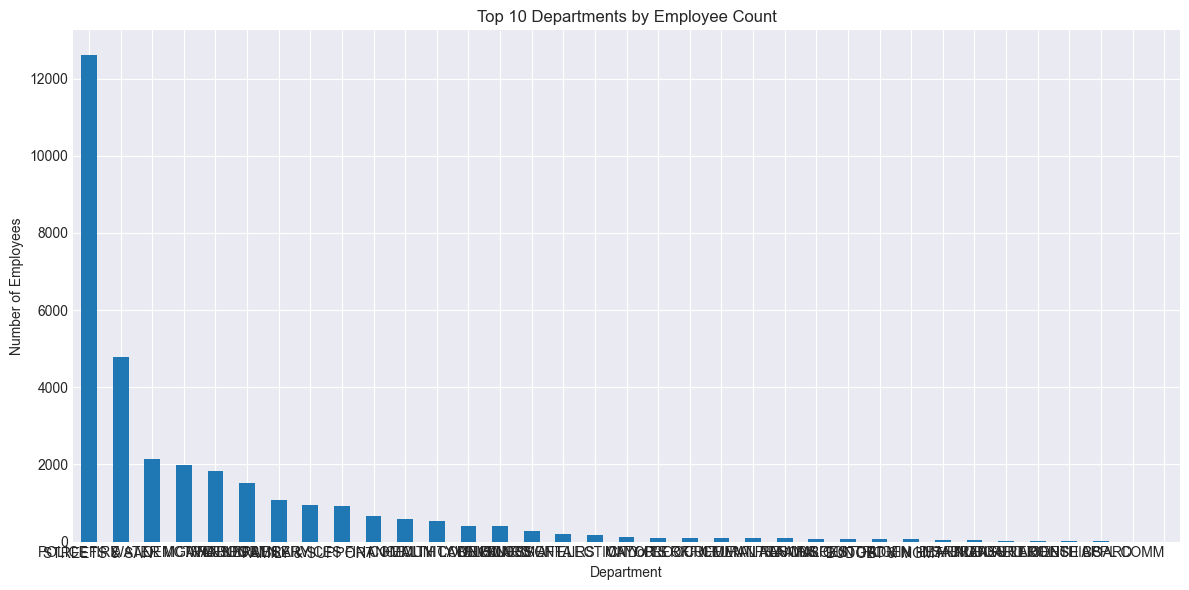

In [114]:
# Top 10 departments by employee count
dept_counts = chicago['Department'].value_counts()
dept_counts.plot(kind='bar', figsize=(12, 6), title='Top 10 Departments by Employee Count')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0, ha='right')
plt.tight_layout()
plt.show()

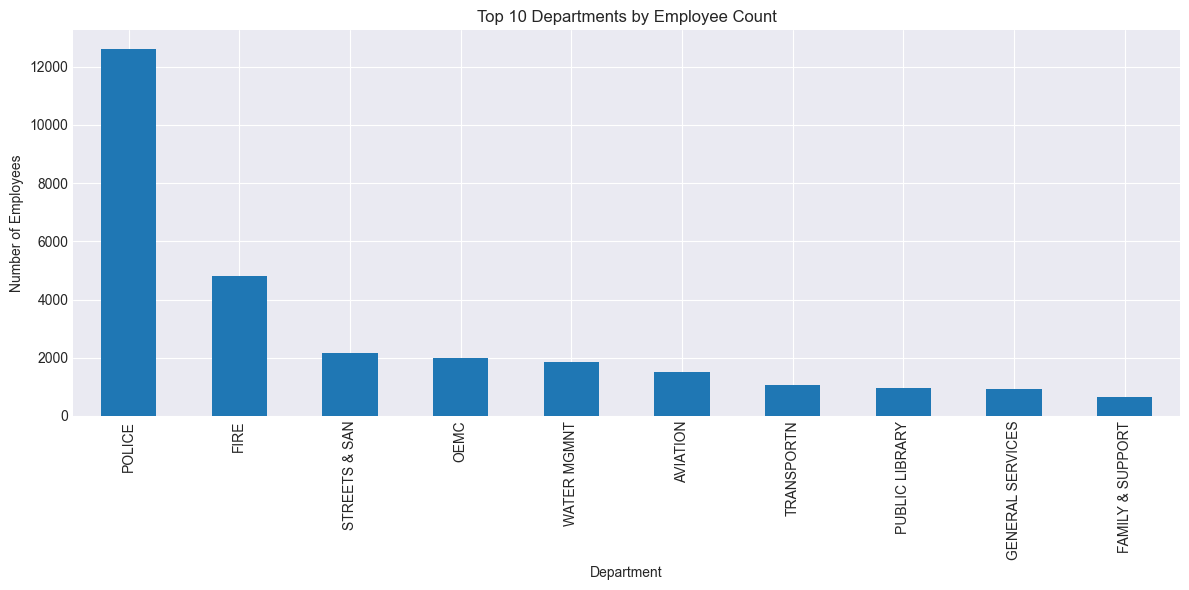

In [116]:
# Top 10 departments by employee count
dept_counts = chicago['Department'].value_counts().head(10)
dept_counts.plot(kind='bar', figsize=(12, 6), title='Top 10 Departments by Employee Count')
plt.xlabel('Department')
plt.ylabel('Number of Employees')

plt.tight_layout()
plt.show()

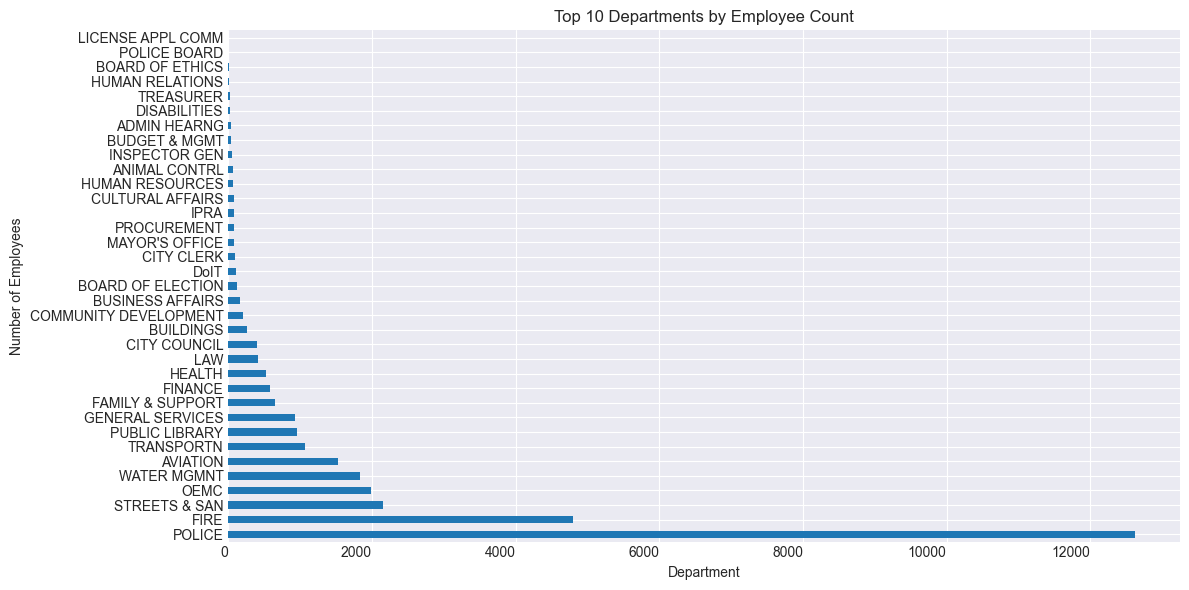

In [117]:
# Top 10 departments by employee count
dept_counts = chicago['Department'].value_counts()
dept_counts.plot(kind='barh', figsize=(12, 6), title='Top 10 Departments by Employee Count')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0, ha='right')
plt.tight_layout()
plt.show()

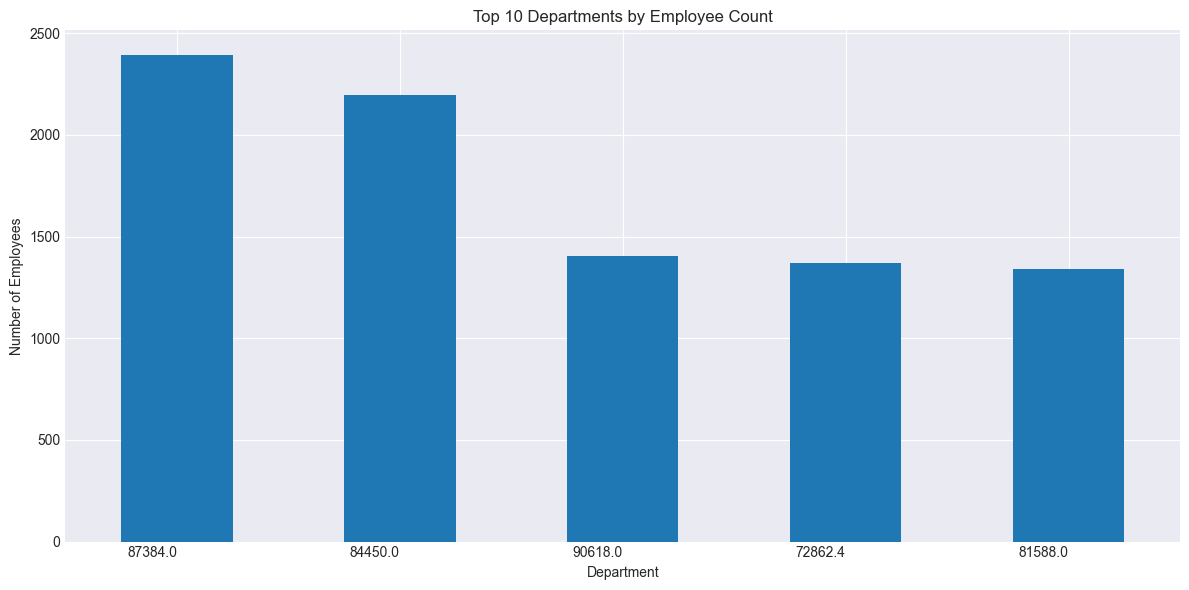

In [122]:
# Top 10 departments by salary count
dept_counts = chicago['Salary'].value_counts().head()
dept_counts.plot(kind='bar', figsize=(12, 6), title='Top 10 Departments by Employee Count')
plt.xlabel('Department')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0, ha='right')
plt.tight_layout()
plt.show()

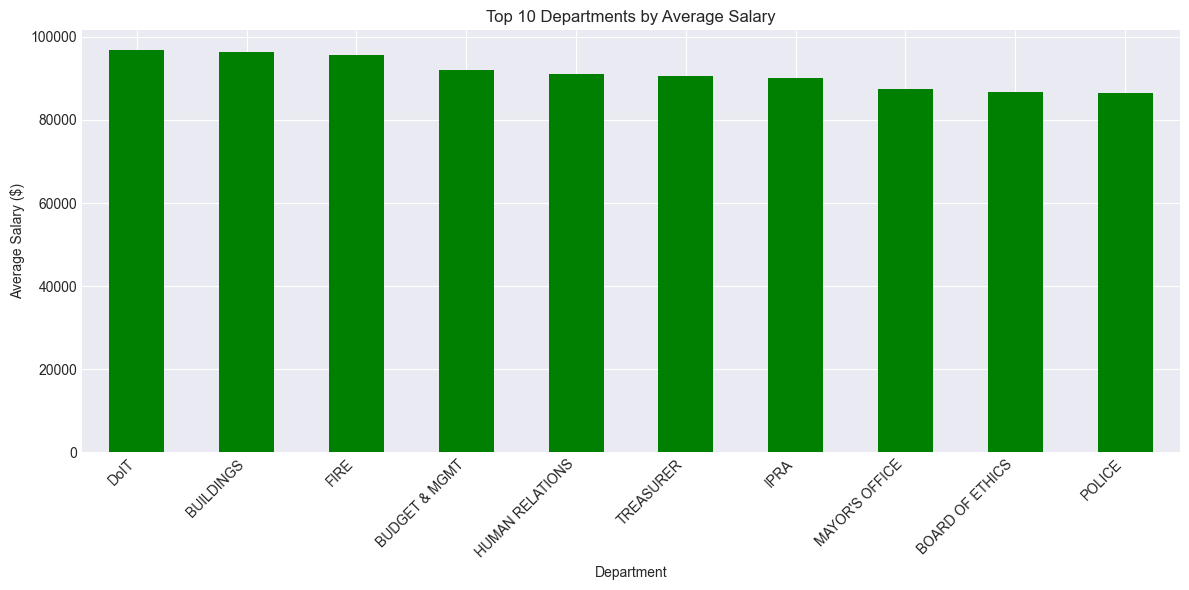

In [123]:
# Top 10 departments by average salary
dept_avg_salary = chicago.groupby('Department')['Salary'].mean().sort_values(ascending=False).head(10)
dept_avg_salary.plot(kind='bar', figsize=(12, 6), color='green', title='Top 10 Departments by Average Salary')
plt.xlabel('Department')
plt.ylabel('Average Salary ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [126]:
chicago["Salary"].max()

np.float64(300000.0)

### 6.2 Histograms

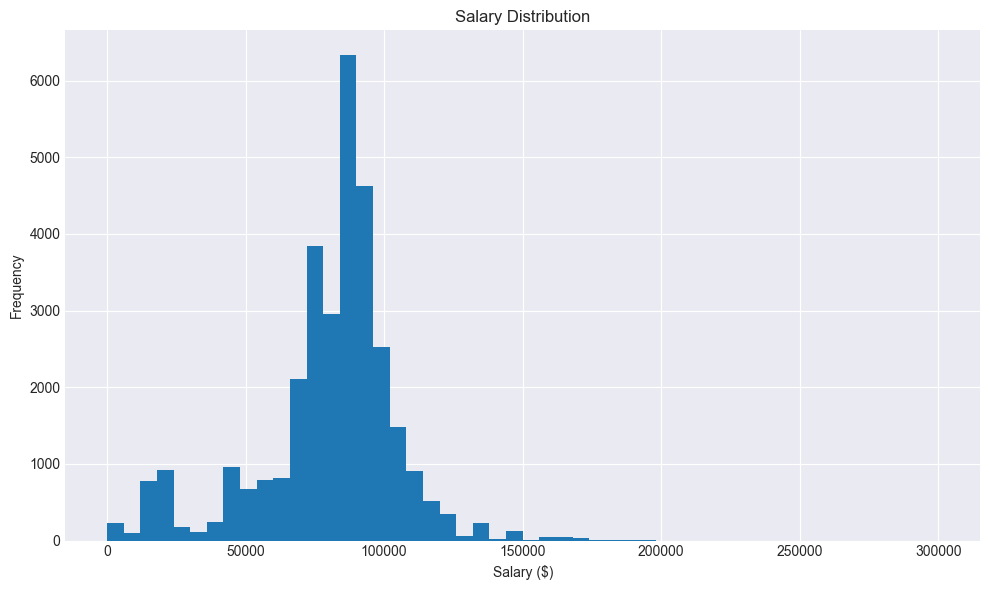

In [125]:
# Salary distribution
chicago['Salary'].plot(kind='hist', bins=50, figsize=(10, 6), title='Salary Distribution')
plt.xlabel('Salary ($)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()


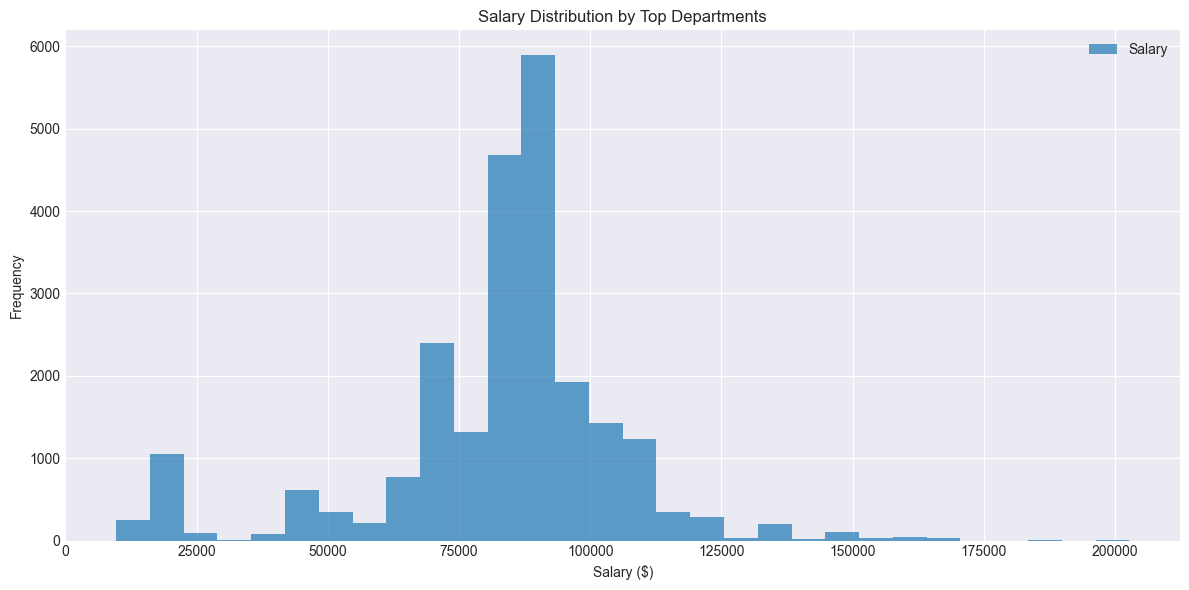

In [107]:
# Salary distribution by department (subset)
top_depts = chicago['Department'].value_counts().head(5).index
chicago[chicago['Department'].isin(top_depts)]['Salary'].plot(
    kind='hist', bins=30, figsize=(12, 6), alpha=0.7, title='Salary Distribution by Top Departments',
    legend=True
)
plt.xlabel('Salary ($)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

In [ ]:
chi

### 6.3 Box Plots

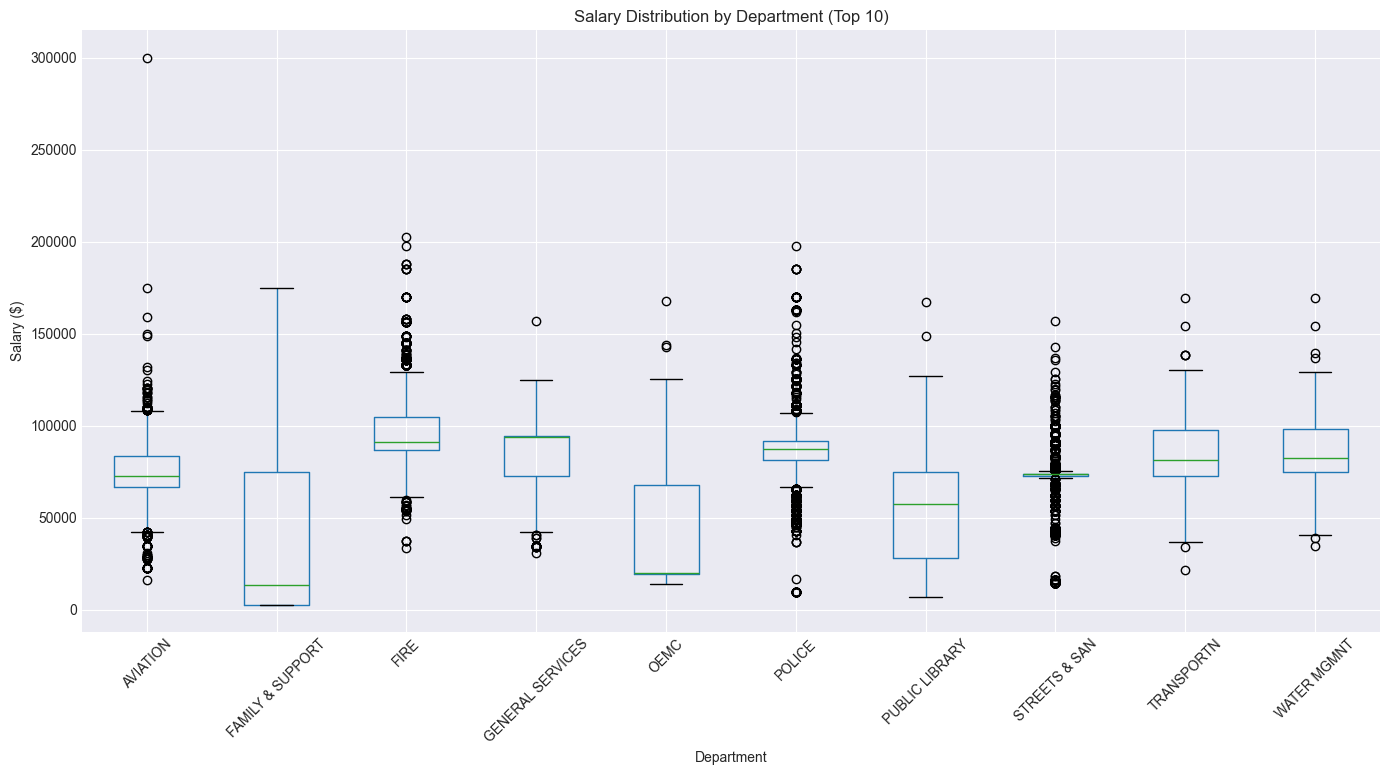

In [108]:
# Box plot of salaries by department (top 10)
top_depts_by_count = chicago['Department'].value_counts().head(10).index
chicago[chicago['Department'].isin(top_depts_by_count)].boxplot(
    column='Salary', by='Department', figsize=(14, 8), rot=45
)
plt.title('Salary Distribution by Department (Top 10)')
plt.suptitle('')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

### 6.4 Scatter Plots

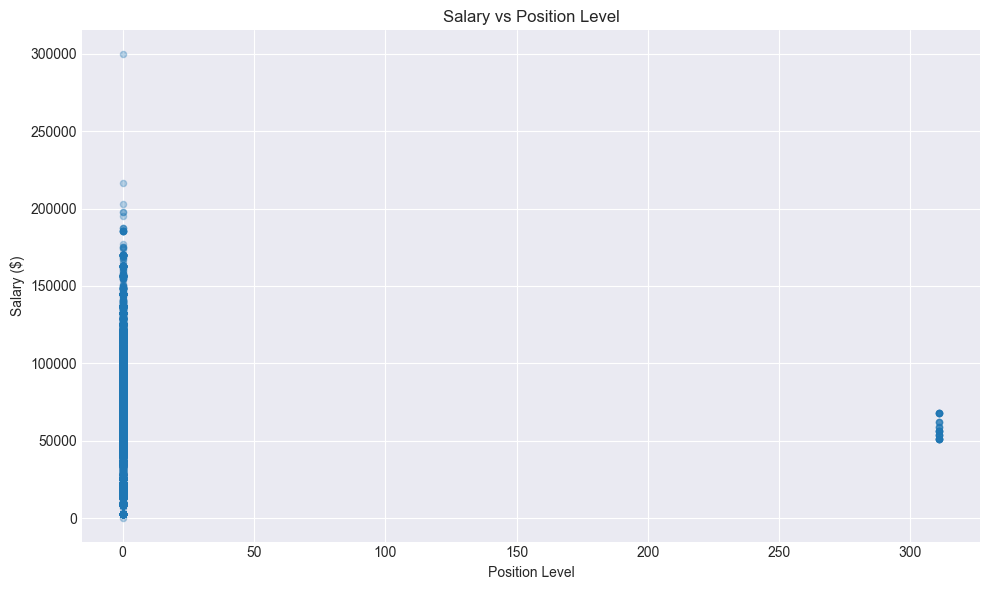

In [127]:
# Scatter plot: Salary vs Position Level (simulated)
# Create a simple position level indicator
chicago['Pos_Level'] = chicago['Position Title'].str.extract(r'(\d+)$').fillna(0).astype(int)

chicago.plot(
    kind='scatter', x='Pos_Level', y='Salary',
    figsize=(10, 6), alpha=0.3, title='Salary vs Position Level'
)
plt.xlabel('Position Level')
plt.ylabel('Salary ($)')
plt.tight_layout()
plt.show()

### 6.5 Line Plots

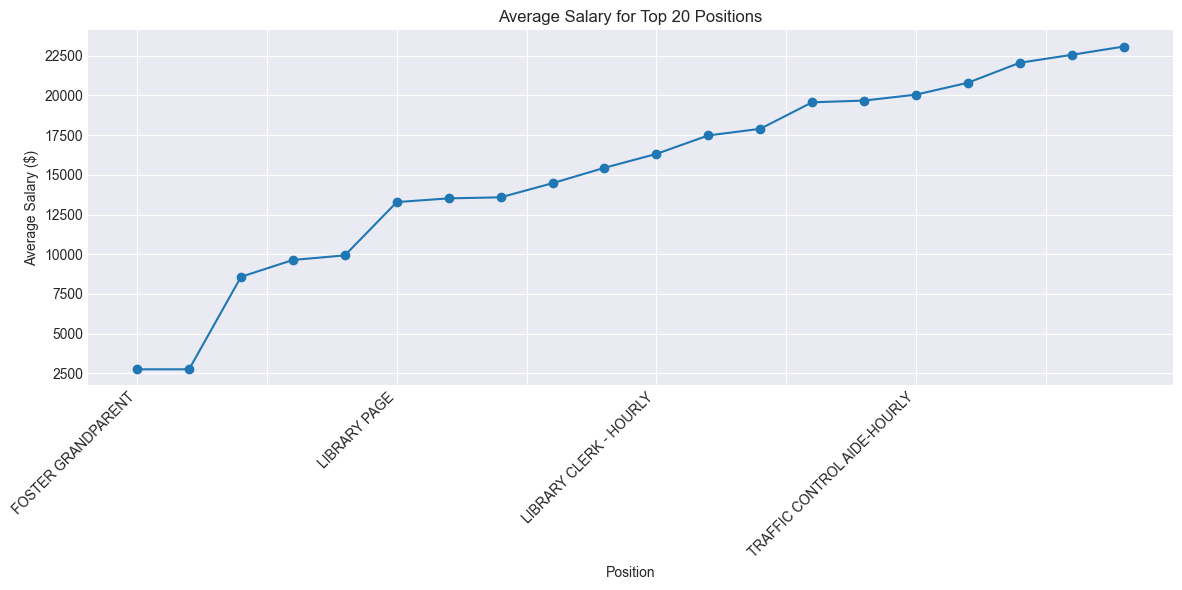

In [110]:
# Average salary trend by position (simulated ordering)
pos_avg = chicago.groupby('Position Title')['Salary'].mean().sort_values(ascending=True).head(20)
pos_avg.plot(kind='line', figsize=(12, 6), marker='o', title='Average Salary for Top 20 Positions')
plt.xlabel('Position')
plt.ylabel('Average Salary ($)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

### 6.6 Pie Charts

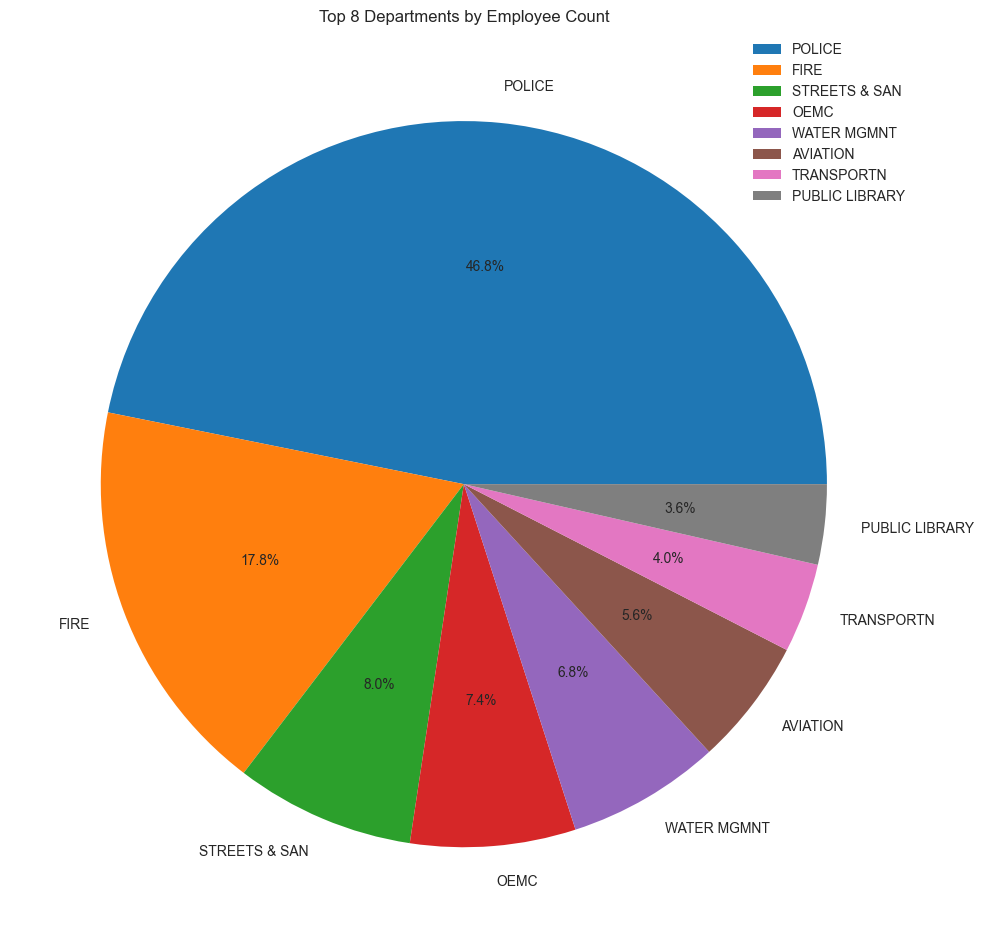

In [128]:
# Top 8 departments by employee count (pie chart)
top_8_depts = chicago['Department'].value_counts().head(8)
top_8_depts.plot(
    kind='pie', figsize=(10, 10), autopct='%1.1f%%',
    title='Top 8 Departments by Employee Count', legend=True
)
plt.tight_layout()
plt.show()

### 6.7 Advanced Visualizations with Subplots

ValueError: not enough values to unpack (expected 2, got 0)

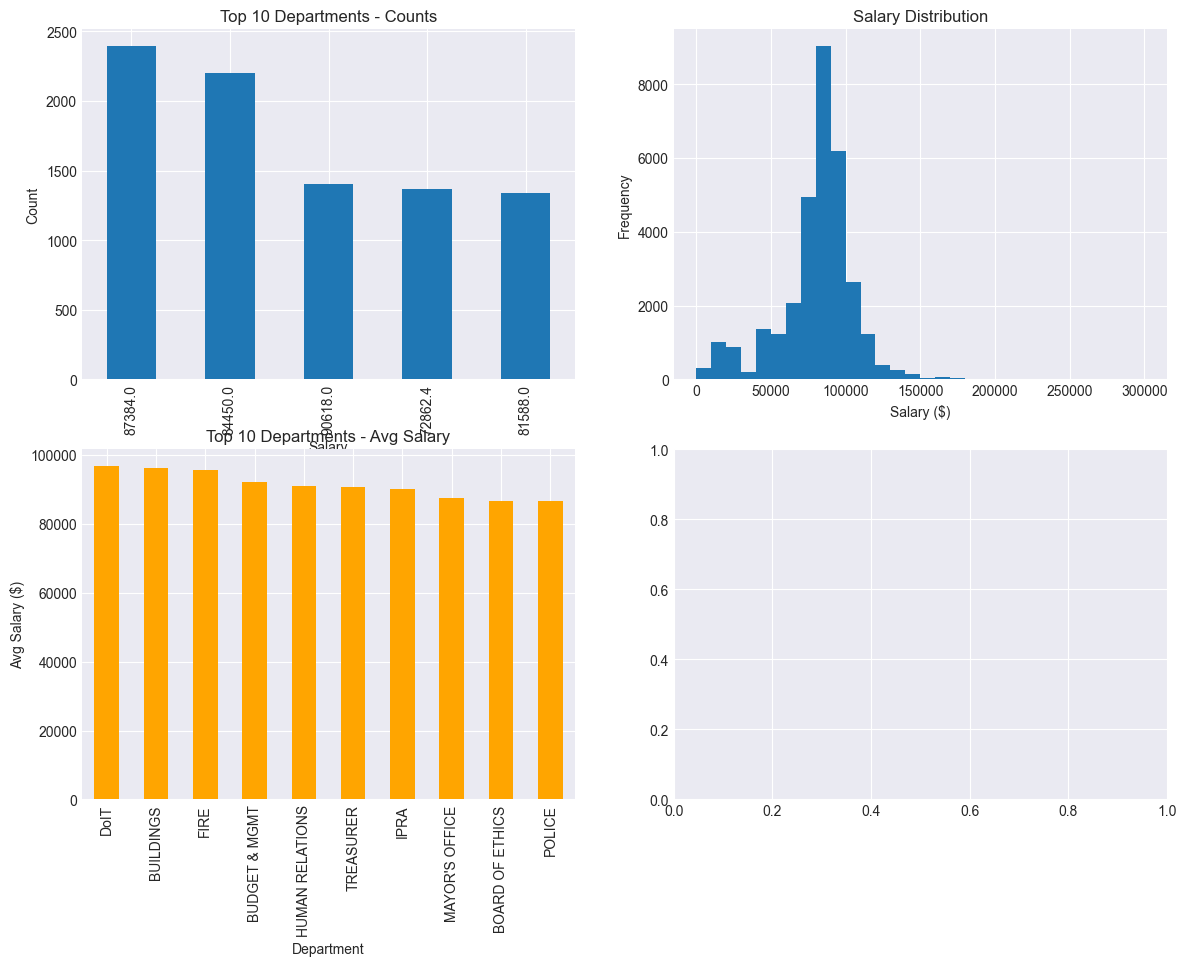

In [129]:
# Multiple plots in one figure
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Department counts
dept_counts.head(10).plot(kind='bar', ax=axes[0, 0], title='Top 10 Departments - Counts')
axes[0, 0].set_ylabel('Count')

# Plot 2: Salary histogram
chicago['Salary'].plot(kind='hist', ax=axes[0, 1], bins=30, title='Salary Distribution')
axes[0, 1].set_xlabel('Salary ($)')

# Plot 3: Average salary by top departments
dept_avg_salary = chicago.groupby('Department')['Salary'].mean().sort_values(ascending=False).head(10)
dept_avg_salary.plot(kind='bar', ax=axes[1, 0], color='orange', title='Top 10 Departments - Avg Salary')
axes[1, 0].set_ylabel('Avg Salary ($)')

# Plot 4: Box plot for top 5 departments
top5_depts = dept_counts.head(5).index
chicago[chicago['Department'].isin(top5_depts)].boxplot(
    column='Salary', by='Department', ax=axes[1, 1]
)
axes[1, 1].set_title('Salary Distribution by Top 5 Departments')
axes[1, 1].set_ylabel('Salary ($)')
axes[1, 1].set_xlabel('Department')

plt.suptitle('Chicago Employee Data Analysis', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

## 7. Practical Exercises

### Exercise 1: Text Processing
Q: Create a new column `Salary_Band` that categorizes employees into 'Low', 'Medium', 'High' based on salary percentiles.

In [ ]:
# Solution
percentiles = chicago['Salary'].quantile([0.33, 0.67])

def salary_band(salary):
    if salary <= percentiles[0.33]:
        return 'Low'
    elif salary <= percentiles[0.67]:
        return 'Medium'
    else:
        return 'High'

chicago['Salary_Band'] = chicago['Salary'].apply(salary_band)
chicago['Salary_Band'].value_counts()

### Exercise 2: MultiIndex
Q: Create a MultiIndex DataFrame with Department and Position Title, showing the count and average salary.

In [ ]:
# Solution
multi_summary = chicago.groupby(['Department', 'Position Title']).agg(
    Count=('Salary', 'count'),
    Avg_Salary=('Salary', 'mean')
)
multi_summary.head(10)

### Exercise 3: Merging
Q: Create department summaries and merge with employee data to show % of total department employees.

In [ ]:
# Solution
dept_summary = chicago.groupby('Department').agg(
    Total_Employees=('Salary', 'count'),
    Avg_Salary=('Salary', 'mean')
).reset_index()

# Calculate percentage of total
total_employees = dept_summary['Total_Employees'].sum()
dept_summary['Pct_Of_Total'] = (dept_summary['Total_Employees'] / total_employees * 100).round(2)

dept_summary.head(10)

### Exercise 4: Visualization
Q: Create a dashboard with 4 plots showing different aspects of the data.

In [ ]:
# Solution
fig, axes = plt.subplots(2, 2, figsize=(15, 12))

# 1. Department distribution
dept_counts.head(10).plot(kind='barh', ax=axes[0, 0], color='steelblue')
axes[0, 0].set_title('Top 10 Departments by Employee Count')
axes[0, 0].set_xlabel('Number of Employees')

# 2. Salary distribution by Salary Band
chicago.groupby('Salary_Band')['Salary'].mean().plot(
    kind='bar', ax=axes[0, 1], color=['green', 'yellow', 'red']
)
axes[0, 1].set_title('Average Salary by Salary Band')
axes[0, 1].set_ylabel('Average Salary ($)')

# 3. Salary histogram
chicago['Salary'].plot(kind='hist', bins=40, ax=axes[1, 0], color='purple', alpha=0.7)
axes[1, 0].set_title('Salary Distribution')
axes[1, 0].set_xlabel('Salary ($)')
axes[1, 0].set_ylabel('Frequency')

# 4. Box plot by Department (top 5)
top5 = chicago['Department'].value_counts().head(5).index
chicago[chicago['Department'].isin(top5)].boxplot(
    column='Salary', by='Department', ax=axes[1, 1]
)
axes[1, 1].set_title('Salary Distribution by Department (Top 5)')
axes[1, 1].set_ylabel('Salary ($)')

plt.suptitle('Chicago Employee Data Dashboard', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 8. Summary

### Key Takeaways:

1. **Text Data**: Use `.str` accessor for string operations like `contains`, `split`, `replace`
2. **MultiIndex**: Hierarchical indexing for complex data structures using `set_index` and `xs`
3. **Merging**: Combine DataFrames using `merge` with different join types (`inner`, `left`, `right`, `outer`)
4. **GroupBy**: Powerful aggregation using `groupby` with `agg`, `transform`, and `apply`
5. **Input/Output**: Read/write various formats including CSV, Excel, JSON, and Parquet
6. **Visualizations**: Quick plotting with pandas `.plot()` for exploratory data analysis